# 05 · Walk-forward validation

**Question:** notebook 04 showed what every parameter combination earned over one history, in sample. If the parameters had instead been chosen each year from the data available at the time, what would that have earned afterwards?

**Short answer:** less than not choosing at all. Out of sample (2012-2026), all four walk-forward portfolios have a lower Sharpe ratio than equal weight (0.75 to 0.84 against 0.89) and than the parameters fixed in advance (0.83 to 0.93). None of the differences is statistically significant, in either direction. The reason is visible in the selections themselves: **the configuration with the best track record lands, the following year, at the 49th to 59th percentile of its own grid**, which is where a configuration drawn at random would land. Past Sharpe ratio carries no usable information about which parameters will do better next year.

The "researcher" who chooses among all 65 sector configurations picks a trend-following window every single year, and so earns exactly what the trend-following walk-forward earns: a Sharpe of 0.84 with a CAGR of 7.8%, against 13.5% for equal weight.

Rules of this notebook:
- It only imports from `backtester` and presents results; the logic lives in `src/` with its tests.
- The design (window, length, dates, selection criterion) was fixed before running anything and is described in section 1. One secondary variant was also declared in advance and is reported in section 6 without being used for the conclusions.
- Each walk-forward is one more configuration tried: the project's count goes from 98 (notebook 04) to 106.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from backtester import BacktestResult, ProportionalCosts, run_backtest
from backtester.data import load_prices
from backtester.metrics import drawdown, sharpe
from backtester.report import compare
from backtester.significance import (
    bootstrap_sharpe_difference,
    holm_adjust,
    ledoit_wolf_sharpe_test,
)
from backtester.strategies import CrossSectionalMomentum, MeanReversion, TrendFollowing
from backtester.strategy import EqualWeight, Strategy
from backtester.walk_forward import WalkForward, splice_returns

SECTOR_ETFS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
START, END = "2005-01-01", "2026-10-31"  # fixed end date: reproducible numbers
COSTS = ProportionalCosts(bps=5)
REBALANCE = "ME"
MIN_TRAINING_DAYS = 5 * 252  # fixed in advance: at least five years before the first choice
BENCHMARK = "Equal weight"
RESEARCHER = "All configurations"
IMG_DIR = Path("../docs/img")

In [2]:
sectors = load_prices(SECTOR_ETFS, start=START, end=END)
print(f"{sectors.shape[0]} sessions, from {sectors.index[0].date()} to {sectors.index[-1].date()}")

5492 sessions, from 2005-01-03 to 2026-10-30


## 1. Design, fixed in advance

- **Candidates:** the grids of notebook 04 (30 momentum, 25 mean reversion and 10 trend-following configurations), each backtested with 5 bps of costs and monthly rebalancing. A fourth walk-forward, the "researcher", chooses among all 65 at once, which is what someone looking for the best strategy would actually do.
- **Criterion:** at the last close of each year, the candidate with the highest Sharpe ratio after costs over the training window.
- **Window: expanding**, from the first day on which every candidate is invested (2006-08-01), with at least five years of data before the first choice. The argument for expanding over rolling is noise: the standard error of a Sharpe ratio estimated on five years is about 0.5, several times the differences between cells of a grid (around 0.1), so the selection needs all the data it can get. A rolling window is the right tool when the best parameter is expected to change over time, and there was no prior reason to expect that here.
- **Timing:** the chosen configuration gives its first order at that same last close of the year, using data up to that close, and earns its first return on the first session of the new year. This is the engine's usual convention (decide at the close of *t*, earn the return of *t*+1).
- **One pass through the engine:** the weights of the selected configurations are joined and backtested once, so moving from one configuration to another is a trade and pays its turnover.

With these rules the first choice is made at the close of 2011 and the out-of-sample period is 2012-01-03 to 2026-10-30: 15 years, the last one partial.

In [3]:
# The same grids as notebook 04, one strategy object per cell.
TOP_N = [1, 2, 3, 4, 5]
families = {
    "Momentum": {
        f"Momentum ({lookback}, {top_n})": CrossSectionalMomentum(lookback=lookback, top_n=top_n)
        for lookback in [63, 126, 189, 252, 315, 378]
        for top_n in TOP_N
    },
    "Mean reversion": {
        f"Mean reversion ({lookback}, {top_n})": MeanReversion(lookback=lookback, top_n=top_n)
        for lookback in [5, 10, 20, 40, 60]
        for top_n in TOP_N
    },
    "Trend following": {
        f"Trend following ({window})": TrendFollowing(window=window)
        for window in [50, 75, 100, 125, 150, 175, 200, 225, 250, 300]
    },
}
# The "researcher" chooses among every sector configuration at once.
families[RESEARCHER] = {
    label: strategy for group in list(families.values()) for label, strategy in group.items()
}
# The values fixed in advance in notebooks 01-02.
DEFAULTS = {
    "Momentum": "Momentum (252, 3)",
    "Mean reversion": "Mean reversion (20, 3)",
    "Trend following": "Trend following (200)",
}
pd.Series({name: len(group) for name, group in families.items()}, name="Candidates").to_frame()

,Candidates
Momentum,30
Mean reversion,25
Trend following,10
All configurations,65


In [4]:
def walk_forwards(rolling_days: int | None = None) -> dict[str, WalkForward]:
    # Training data starts on the same day for all four: the first day on which the slowest
    # of the 65 configurations is invested.
    slowest = WalkForward(families[RESEARCHER], COSTS, REBALANCE, MIN_TRAINING_DAYS)
    train_start = slowest.candidate_returns(sectors).index[0]
    return {
        name: WalkForward(
            group, COSTS, REBALANCE, MIN_TRAINING_DAYS, rolling_days=rolling_days, start=train_start
        )
        for name, group in families.items()
    }


walks = walk_forwards()  # expanding window: the primary design
candidate_returns = {name: walk.candidate_returns(sectors) for name, walk in walks.items()}
selections = {name: walk.selection(sectors) for name, walk in walks.items()}

train_start = candidate_returns[RESEARCHER].index[0]
first_choice = selections[RESEARCHER].index[0]
oos_start = sectors.index[sectors.index.get_loc(first_choice) + 1]
print(
    f"Training data from {train_start.date()}; first choice at the close of {first_choice.date()}"
)
print(f"Out of sample: {oos_start.date()} to {sectors.index[-1].date()}")

Training data from 2006-08-01; first choice at the close of 2011-12-30
Out of sample: 2012-01-03 to 2026-10-30


## 2. What was selected

Each row is the configuration chosen at the end of the previous year and traded during that year.

In [5]:
chosen = pd.DataFrame({name: table["selected"] for name, table in selections.items()})
chosen.index = (chosen.index.year + 1).rename("Traded in")
chosen

,Momentum,Mean reversion,Trend following,All configurations
Traded in,,,,
2012,"Momentum (126, 4)","Mean reversion (5, 1)",Trend following (100),Trend following (100)
2013,"Momentum (126, 4)","Mean reversion (5, 1)",Trend following (100),Trend following (100)
2014,"Momentum (126, 4)","Mean reversion (5, 1)",Trend following (100),Trend following (100)
2015,"Momentum (126, 4)","Mean reversion (5, 1)",Trend following (100),Trend following (100)
2016,"Momentum (126, 5)","Mean reversion (10, 3)",Trend following (150),Trend following (150)
2017,"Momentum (126, 4)","Mean reversion (10, 3)",Trend following (150),Trend following (150)
2018,"Momentum (126, 5)","Mean reversion (10, 3)",Trend following (150),Trend following (150)
2019,"Momentum (126, 5)","Mean reversion (10, 3)",Trend following (150),Trend following (150)
2020,"Momentum (126, 5)","Mean reversion (10, 3)",Trend following (200),Trend following (200)


In [6]:
def stability(table: pd.DataFrame) -> dict:
    selected = table["selected"]
    return {
        "Years": len(selected),
        "Changes of configuration": int((selected != selected.shift()).iloc[1:].sum()),
        "Different configurations used": selected.nunique(),
        "Most used": selected.mode().iloc[0],
        "Years with the most used": int(selected.value_counts().iloc[0]),
    }


pd.DataFrame({name: stability(table) for name, table in selections.items()}).T

,Years,Changes of configuration,Different configurations used,Most used,Years with the most used
Momentum,15,8,4,"Momentum (126, 4)",7
Mean reversion,15,2,3,"Mean reversion (5, 5)",6
Trend following,15,3,4,Trend following (175),6
All configurations,15,3,4,Trend following (175),6


- **Trend following and the researcher are the same portfolio.** A trend-following window had the best training Sharpe of all 65 configurations in every one of the 15 years, so the two walk-forwards make identical choices. Notebook 04 explains why: trend following is only partly invested (75% on average in notebook 02), and its Sharpe ratio (not its return) was the highest of the three families over a history that contains 2008.
- **Momentum's choice keeps moving** (8 changes in 15 years, between cells that are far apart in the grid, such as (126, 4) and (378, 2)). When the top of the ranking changes hands this easily, the ranking is noise.
- **None of the walk-forwards ever chose the momentum or mean-reversion values fixed in advance**, and trend following chose its own (200) in one year out of 15. In particular, momentum (252, 3), the best cell of its grid over the full sample in notebook 04, was never the best at any year end. Its full-sample lead was built late and could not have been used.

## 3. Out-of-sample results

Everything below is measured over the same days, 2012-01-03 to 2026-10-30. "Pre-fixed" is the configuration of notebooks 01-02 held throughout. In the plot the trend-following line is hidden behind the researcher's, which is identical.

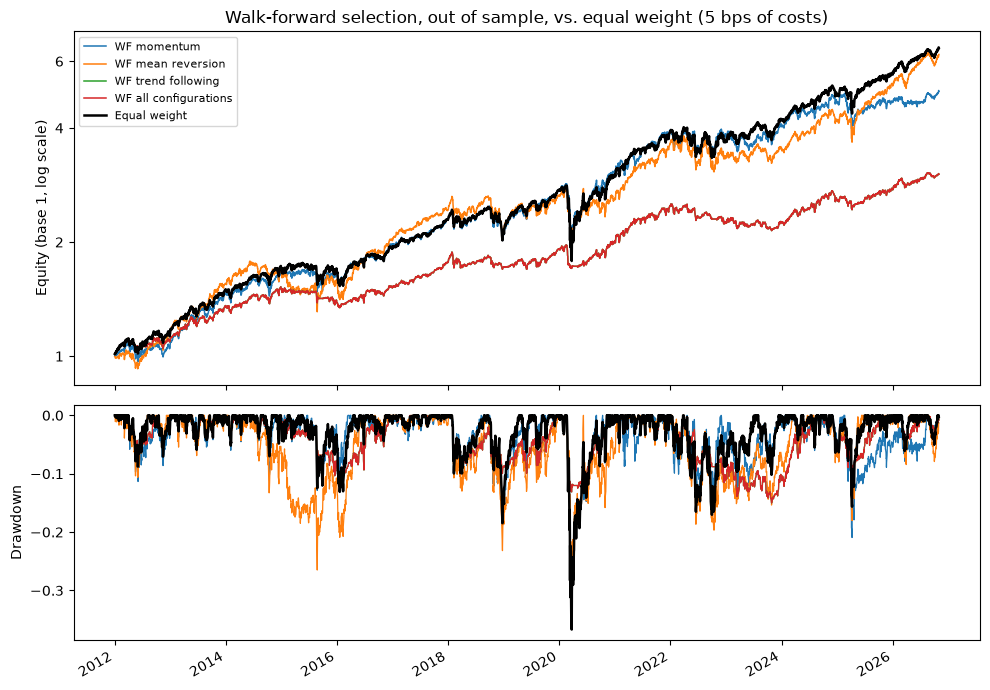

In [7]:
def run(strategy: Strategy) -> BacktestResult:
    return run_backtest(sectors, strategy, COSTS, rebalance=REBALANCE).since(oos_start)


wf = {f"WF {name.lower()}": run(walk) for name, walk in walks.items()}
defaults = {f"{name}, pre-fixed": run(families[name][label]) for name, label in DEFAULTS.items()}
benchmark = run(EqualWeight())
results = {**wf, **defaults, BENCHMARK: benchmark}

shown = {**wf, BENCHMARK: benchmark}
equity = pd.DataFrame({name: result.equity for name, result in shown.items()})
drawdowns = pd.DataFrame({name: drawdown(result.returns) for name, result in shown.items()})
styles = {BENCHMARK: {"color": "black", "lw": 1.8}}

fig, (ax_equity, ax_drawdown) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]}
)
for name in equity:
    equity[name].plot(ax=ax_equity, **styles.get(name, {"lw": 1.1}), label=name)
    drawdowns[name].plot(ax=ax_drawdown, **styles.get(name, {"lw": 0.9}), legend=False)
ax_equity.set_yscale("log")
ax_equity.set_yticks([1, 2, 4, 6], labels=["1", "2", "4", "6"])
ax_equity.minorticks_off()
ax_equity.set_ylabel("Equity (base 1, log scale)")
ax_equity.set_title("Walk-forward selection, out of sample, vs. equal weight (5 bps of costs)")
ax_equity.legend(fontsize=8)
ax_drawdown.set_ylabel("Drawdown")
ax_drawdown.set_xlabel("")
fig.tight_layout()
IMG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(IMG_DIR / "walk_forward.png", dpi=150)
plt.show()

In [8]:
rows = ["CAGR", "Annual volatility", "Sharpe", "Max drawdown", "Annual turnover", "Annual costs"]
compare(results).loc[rows].T.round(3)

,CAGR,Annual volatility,Sharpe,Max drawdown,Annual turnover,Annual costs
WF momentum,0.115,0.164,0.745,-0.358,5.861,0.003
WF mean reversion,0.132,0.172,0.807,-0.349,15.022,0.008
WF trend following,0.078,0.094,0.840,-0.150,2.570,0.001
WF all configurations,0.078,0.094,0.840,-0.150,2.570,0.001
"Momentum, pre-fixed",0.142,0.167,0.880,-0.303,5.092,0.003
"Mean reversion, pre-fixed",0.139,0.175,0.834,-0.349,15.885,0.008
"Trend following, pre-fixed",0.089,0.097,0.927,-0.150,1.890,0.001
Equal weight,0.135,0.156,0.889,-0.367,0.288,0.000


All four walk-forwards are below equal weight in Sharpe ratio, and all three single-family ones are below their own pre-fixed configuration. Momentum loses most from being tuned (0.75 against 0.88). Trend following keeps its small drawdown (−15%) and its low return: 7.8% a year against 13.5% for equal weight, in a period with no 2008 in it.

## 4. Does switching cost anything?

The engine charges the trade from one configuration to the next. The reference below joins the selected configurations' own backtests instead, as if each had already been held on its first day: a walk-forward built that way would switch for free.

In [9]:
def switching(name: str) -> dict:
    result = wf[f"WF {name.lower()}"]
    spliced = splice_returns(candidate_returns[name], selections[name]["selected"])
    return {
        "Sharpe through the engine": sharpe(result.returns),
        "Sharpe if switching were free": sharpe(spliced),
        "Return lost to switching, % a year": (spliced.mean() - result.returns.mean()) * 252 * 100,
        "Annual turnover": result.turnover.mean() * 252,
    }


pd.DataFrame({name: switching(name) for name in walks}).T.round(3)

,Sharpe through the engine,Sharpe if switching were free,"Return lost to switching, % a year",Annual turnover
Momentum,0.745,0.746,0.016,5.861
Mean reversion,0.807,0.807,-0.003,15.022
Trend following,0.840,0.840,0.004,2.570
All configurations,0.840,0.840,0.004,2.570


Almost nothing: at most 0.02% a year. Two reasons. The switch happens at a month end, when the portfolio is rebalanced anyway. And changes are rare, 2 to 8 in 15 years. Running the weights through the engine is still the correct way to do it, and the test suite has a case where the difference is large, but here it is not what hurts.

## 5. Why selection does not help

For each year, every candidate's Sharpe ratio in that year is computed, and the chosen one is placed among them. If past performance identified better parameters, the chosen configuration would sit well above the middle of its grid the following year.

In [10]:
def decay(name: str) -> dict:
    # Sharpe of every candidate in each calendar year, then where the chosen one landed.
    returns = candidate_returns[name].loc[oos_start:]
    by_year = returns.groupby(returns.index.year).apply(lambda year: year.apply(sharpe))
    picked = selections[name].set_axis(selections[name].index.year + 1)
    labels = picked["selected"]
    next_year = pd.Series({year: by_year.loc[year, label] for year, label in labels.items()})
    rank = pd.Series(
        {year: by_year.loc[year].rank(pct=True)[label] for year, label in labels.items()}
    )
    return {
        "Sharpe of the chosen one in training (mean)": picked["train_sharpe"].mean(),
        "Its Sharpe the next year (mean)": next_year.mean(),
        "Median candidate the next year (mean)": by_year.median(axis=1).mean(),
        "Best candidate the next year (mean)": by_year.max(axis=1).mean(),
        "Percentile of the chosen one the next year (mean)": rank.mean(),
        "Years above the median candidate": f"{int((rank > 0.5).sum())} of {len(rank)}",
    }


pd.DataFrame({name: decay(name) for name in walks}).T.infer_objects().round(2)

,Sharpe of the chosen one in training (mean),Its Sharpe the next year (mean),Median candidate the next year (mean),Best candidate the next year (mean),Percentile of the chosen one the next year (mean),Years above the median candidate
Momentum,0.58,0.96,0.91,1.62,0.52,7 of 15
Mean reversion,0.62,1.12,1.05,1.67,0.59,8 of 15
Trend following,0.82,0.89,0.92,1.14,0.51,7 of 15
All configurations,0.82,0.89,1.00,1.90,0.49,8 of 15


- **The chosen configuration is an average one the next year.** Its mean percentile within its own grid is 0.49 to 0.59 (0.5 is the middle) and it beats the median candidate in 7 or 8 years out of 15, a coin flip.
- **The room for improvement was there.** The best candidate of each year has a Sharpe ratio 0.2 to 0.9 above the median one. Selection on past Sharpe captures none of it.
- The level of these yearly figures is not the point: they are averages of one-year Sharpe ratios in a strong market, higher than the training figures, which include 2008. The comparison that matters is within each column: chosen against median. The last year, 2026, is partial (ten months).

## 6. Are the differences significant?

Seven comparisons: each single-family walk-forward against its pre-fixed configuration, and each of the four against equal weight. Paired stationary bootstrap and Ledoit-Wolf HAC test, as in the earlier notebooks, with the Holm correction across the seven.

In [11]:
comparisons = [(f"WF {name.lower()}", f"{name}, pre-fixed") for name in DEFAULTS]
comparisons += [(name, BENCHMARK) for name in wf]

rows = {}
for challenger, reference in comparisons:
    a, b = results[challenger].returns, results[reference].returns
    boot = bootstrap_sharpe_difference(a, b, n_boot=10_000, seed=0)
    hac = ledoit_wolf_sharpe_test(a, b)
    rows[f"{challenger} vs. {reference.lower()}"] = {
        "Sharpe difference": boot.estimate,
        "Bootstrap 95% CI low": boot.ci_low,
        "Bootstrap 95% CI high": boot.ci_high,
        "Bootstrap p": boot.p_value,
        "Ledoit-Wolf p": hac.p_value,
    }
tests = pd.DataFrame(rows).T
tests.insert(4, "Bootstrap p (Holm)", holm_adjust(tests["Bootstrap p"]))
tests["Ledoit-Wolf p (Holm)"] = holm_adjust(tests["Ledoit-Wolf p"])
tests.round(3)

,Sharpe difference,Bootstrap 95% CI low,Bootstrap 95% CI high,Bootstrap p,Bootstrap p (Holm),Ledoit-Wolf p,Ledoit-Wolf p (Holm)
"WF momentum vs. momentum, pre-fixed",-0.135,-0.358,0.095,0.235,1.000,0.249,1.000
"WF mean reversion vs. mean reversion, pre-fixed",-0.026,-0.256,0.198,0.812,1.000,0.793,1.000
"WF trend following vs. trend following, pre-fixed",-0.087,-0.177,0.005,0.060,0.417,0.067,0.467
WF momentum vs. equal weight,-0.144,-0.372,0.031,0.155,0.928,0.142,0.849
WF mean reversion vs. equal weight,-0.082,-0.343,0.135,0.502,1.000,0.435,1.000
WF trend following vs. equal weight,-0.050,-0.327,0.184,0.728,1.000,0.757,1.000
WF all configurations vs. equal weight,-0.050,-0.327,0.184,0.728,1.000,0.757,1.000


**No difference is significant, and every point estimate is negative.** The closest is trend following against its own pre-fixed window (−0.09, raw p = 0.06, Holm 0.42): choosing the window each year did slightly worse than leaving it at 200. So the honest statement is two-sided: walk-forward selection did not help, and the data cannot show that it hurt either. With 15 years the 95% intervals are 0.2 to 0.5 wide, so only a large difference could be detected.

### Secondary variant, declared in advance: a rolling five-year window

Run once, as a check that the conclusion does not depend on the expanding window. It is not used for the conclusions, and its four runs are counted as trials.

In [12]:
rolling_walks = walk_forwards(rolling_days=MIN_TRAINING_DAYS)  # the last five years only
rolling = {}
for name, walk in rolling_walks.items():
    table = walk.selection(sectors)
    rolling[name] = {
        "Sharpe, expanding window (primary)": sharpe(wf[f"WF {name.lower()}"].returns),
        "Sharpe, rolling five years": sharpe(run(walk).returns),
        "Changes, expanding": stability(selections[name])["Changes of configuration"],
        "Changes, rolling": stability(table)["Changes of configuration"],
    }
print(f"Equal weight over the same period: Sharpe {sharpe(benchmark.returns):.3f}")
pd.DataFrame(rolling).T.astype({"Changes, expanding": int, "Changes, rolling": int}).round(3)

Equal weight over the same period: Sharpe 0.889


,"Sharpe, expanding window (primary)","Sharpe, rolling five years","Changes, expanding","Changes, rolling"
Momentum,0.745,0.765,8,9
Mean reversion,0.807,0.748,2,9
Trend following,0.840,0.852,3,5
All configurations,0.840,0.588,3,10


Same picture: all four are below equal weight (0.89). With a rolling window the selection changes far more often (5 to 10 times in 15 years) and the researcher's portfolio, which changes configuration 10 times, does clearly worse (0.59).

## 7. Conclusions

- **Choosing parameters on past performance did not beat fixing them in advance, and did not beat equal weight.** Out of sample, the four walk-forward portfolios have Sharpe ratios of 0.75, 0.81, 0.84 and 0.84, against 0.83 to 0.93 for the pre-fixed configurations and 0.89 for equal weight.
- **The mechanism is absence of persistence.** The best configuration of the past is a median configuration of the next year. That is what notebook 04 predicted from the other side: flat grids, where the differences between cells are smaller than the noise in measuring them.
- **A researcher free to choose among everything ends up in trend following every year**, because it ranks first on Sharpe ratio, and gives up 5.7 points of return a year for a smaller drawdown. Selecting on Sharpe ratio alone picks the portfolio that is only partly invested (75% on average in notebook 02).
- **This closes the argument of the three previous notebooks.** Pre-fixed parameters showed nothing significant (01-03); the best of 98 configurations does not survive a correction for selection (04); and the selection, done honestly in real time, earns less than the benchmark (05).

**Limitations**

- **Fifteen out-of-sample years, one market regime.** 2012-2026 was a long bull market with short crashes. Trend following is designed for a 2008, which is in the training data and not in the test. A different period could rank the portfolios differently.
- **Low power.** The tests cannot tell a Sharpe difference of 0.1 from zero. "Not significantly worse" is all that can be said for the walk-forwards.
- **One selection rule.** Best Sharpe ratio, once a year. A rule that penalized turnover, required a margin before switching or averaged several good cells would be a different strategy and a new set of trials.
- **The candidates were chosen with hindsight.** The grids were designed in notebook 04, after the full sample had been seen. The walk-forward is honest about the choice among them, not about the choice of the menu.
- **Costs** are 5 bps on turnover, with no spread or market impact.

**Next steps**

- More realistic costs: spread and impact proportional to volatility.
- Volatility targeting as a layer on top of any strategy.